# 밥심 다조건 가상 학습 실험

## 요약

50~64세·65세 이상 가상 1인 가구의 밥솥 사용 조건을 바꿔, 개인별 모델을 시간 순서대로 학습하고 훈련에서 보지 않은 조건으로 설정 후보를 확인합니다. 훈련 조건에서 선택한 설정은 **current**입니다. 미공개 조건의 누락 포착률은 현재 30.2%, 선택 후보 30.2%; 정상일 발송 요청률은 현재 3.9%, 선택 후보 3.9%입니다. 이 수치는 설계한 밥솥 사용 중단을 맞힌 비율이지 실제 식사·건강 상태의 정확도가 아닙니다. 실험 설정은 검증 없이 서비스에 적용하지 않습니다.


## 조건과 검증 방법

- 한 가구의 과거 21일을 순서대로 관찰하고 다음 21일을 평가합니다. 가구마다 규칙적인 아침·저녁, 하루 두 번, 격일 사용 중 하나를 가집니다. 연령·행동 확률은 검증용 가정이며 한국 인구의 비율을 뜻하지 않습니다.
- **훈련 조건 4개:** 안정적 사용, 전반적으로 늦은 사용, 자연스러운 미사용 증가, 3일 간격 조리. 현재 설정·확률 기준·늦은 사용 유예·간격 기준·연속 확인 횟수를 비교합니다. 후보는 훈련 가구의 발송 요청에서 `포착률 - 2×정상일 요청률`로만 선택합니다. 이 가중치는 실험 가정입니다.
- **미공개 검증 조건 3개:** 평가 기간의 점진적인 사용 시각 이동, 주말 시각 이동, 자연스러운 건너뜀과 늦은 사용의 결합. 검증 가구의 난수 시드도 훈련과 다릅니다. 검증 결과를 보고 후보를 다시 고르지 않습니다.
- 사용 중단 라벨은 모델 출력과 무관하게 시나리오 생성 전에 정합니다. 외출·연결 단절일은 평가에서 제외합니다. 반복 개방은 사용 묶음으로 처리합니다. 모델의 `check_required`를 실제 `DetectionStateManager`에 전달해 발송 요청을 집계합니다. 전송 성공은 가정하며 실제 보호자 푸시 수신은 재현하지 않습니다.
- 조건 생성기와 라벨은 인위적입니다. 실제 생활에서 밥솥 미사용은 곧 결식·위험이 아닙니다. 합성 집합 크기를 늘려도 현장 성능을 입증할 수 없습니다.


## 재현 가능한 코드

개인 모델: `domain/personal_model/engine.py` · SHA-256 `54a07aec0be987bcb5a070e78a6a0f635ee9b44bb8c4d028a611d815cde8d873`. 알림 상태 관리: `workflow/state_manager.py` · SHA-256 `34daf0d6f1e7bf9a17d4b641012a26a816440c6a8f2eb663702bf0692c929ca4`. 조건 생성기: `ai/condition_matrix_experiment.py` · SHA-256 `4f4d52315699814ed6a9c3253f5393caa23578e34b4c5ed7f3c6d7a71e4b4bea`. 아래 코드가 포함되어 Colab에서 저장소 연결 없이 실행됩니다.


In [1]:
"""Learn expected cooker-use windows from observed lid openings.

This is a small probabilistic model, not a meal detector. Weak population
priors initialize four broad usage windows; covered personal days gradually
dominate them. Missing reports and declared absence never become inactivity.
"""


from datetime import date, datetime, time, timedelta, timezone
from math import atan2, ceil, cos, pi, sin
from typing import Mapping


KST = timezone(timedelta(hours=9))
DAY_MINUTES = 24 * 60
PRIORS = (
    ("slot_1", 8 * 60, 0.35),
    ("slot_2", 13 * 60, 0.45),
    ("slot_3", 19 * 60, 0.40),
    ("slot_4", 30, 0.10),
)
USAGE_GROUP = timedelta(minutes=60)


def _time(value: str) -> datetime:
    parsed = datetime.fromisoformat(value.replace("Z", "+00:00"))
    if parsed.tzinfo is None or parsed.utcoffset() is None:
        raise ValueError("model timestamps require timezone")
    return parsed.astimezone(timezone.utc)


def _minutes(moment: datetime) -> float:
    local = moment.astimezone(KST)
    return local.hour * 60 + local.minute + local.second / 60


def _distance(a: float, b: float) -> float:
    return abs((a - b + DAY_MINUTES / 2) % DAY_MINUTES - DAY_MINUTES / 2)


def _circular_mean(values: list[float], prior: float) -> float:
    angles = [2 * pi * item / DAY_MINUTES for item in [prior, *values]]
    x = sum(cos(angle) for angle in angles)
    y = sum(sin(angle) for angle in angles)
    return atan2(y, x) * DAY_MINUTES / (2 * pi) % DAY_MINUTES


class PersonalUsageModel:
    def __init__(self, *, min_covered_days: int = 7, history_days: int = 28,
                 window_hours: float = 2.0, alert_probability: float = 0.72,
                 late_grace_hours: float = 0.0, interval_quantile: float = 0.95) -> None:
        if min_covered_days < 1 or history_days < min_covered_days:
            raise ValueError("invalid learning window")
        if (not 0 < window_hours <= 3 or not 0 < alert_probability <= 1 or
                not 0 <= late_grace_hours <= 2 or not 0.5 <= interval_quantile <= 0.95):
            raise ValueError("invalid model window or alert probability")
        self.min_covered_days = min_covered_days
        self.history_days = history_days
        self.window = timedelta(hours=window_hours)
        self.alert_probability = alert_probability
        self.late_grace = timedelta(hours=late_grace_hours)
        self.interval_quantile = interval_quantile
        self._devices: dict[tuple[str, str], dict[str, object]] = {}
        self._away_intervals: list[tuple[datetime, datetime]] = []
        self._away_since: datetime | None = None

    @property
    def device_keys(self) -> tuple[tuple[str, str], ...]:
        return tuple(self._devices)

    def _device(self, source: str, device_id: str) -> dict[str, object]:
        return self._devices.setdefault((source, device_id), {
            "opens": [], "raw_opens": [], "coverage": [], "online_since": None,
            "last_seen": None, "evaluations": {}, "trend_evaluations": {},
            "decline_streak": 0, "recovery_streak": 0, "trend_active": False,
        })

    def dump_state(self) -> dict[str, object]:
        devices = []
        for (source, device_id), state in self._devices.items():
            devices.append({
                "source": source, "device_id": device_id,
                "opens": [at.isoformat() for at in state["opens"]],
                "raw_opens": [at.isoformat() for at in state["raw_opens"]],
                "coverage": [[start.isoformat(), end.isoformat()] for start, end in state["coverage"]],
                "online_since": state["online_since"].isoformat() if state["online_since"] else None,
                "last_seen": state["last_seen"].isoformat() if state["last_seen"] else None,
                "evaluations": dict(state["evaluations"]),
                "trend_evaluations": dict(state["trend_evaluations"]),
                "decline_streak": state["decline_streak"],
                "recovery_streak": state["recovery_streak"],
                "trend_active": state["trend_active"],
            })
        return {
            "devices": devices,
            "away_intervals": [[start.isoformat(), end.isoformat()] for start, end in self._away_intervals],
            "away_since": self._away_since.isoformat() if self._away_since else None,
        }

    def load_state(self, stored: Mapping[str, object]) -> None:
        self._devices.clear()
        for item in stored.get("devices", []):
            source, device_id = item["source"], item["device_id"]
            state = self._device(source, device_id)
            # Older snapshots only stored group starts. Treat those as the
            # available observations without inventing the missing raw opens.
            state["raw_opens"] = sorted(_time(at) for at in item.get("raw_opens", item.get("opens", [])))
            state["opens"] = self._group_opens(state["raw_opens"])
            state["coverage"] = [(_time(start), _time(end)) for start, end in item.get("coverage", [])]
            state["evaluations"] = dict(item.get("evaluations", {}))
            state["trend_evaluations"] = dict(item.get("trend_evaluations", {}))
            state["decline_streak"] = int(item.get("decline_streak", 0))
            state["recovery_streak"] = int(item.get("recovery_streak", 0))
            state["trend_active"] = bool(item.get("trend_active", False))
            # A process restart interrupts observed coverage. Close it at the
            # last actual heartbeat; never span an unobserved downtime.
            start = item.get("online_since")
            end = item.get("last_seen")
            if start and end and _time(end) > _time(start):
                state["coverage"].append((_time(start), _time(end)))
            state["online_since"] = None
            state["last_seen"] = _time(end) if end else None
        self._away_intervals = [(_time(start), _time(end)) for start, end in stored.get("away_intervals", [])]
        self._away_since = None
        if stored.get("away_since"):
            # The persisted away flag is reapplied by the host after setup.
            self._away_since = _time(stored["away_since"])

    def set_away(self, away: bool, at: str) -> None:
        moment = _time(at)
        if away and self._away_since is None:
            self._away_since = moment
        elif not away and self._away_since is not None:
            if moment > self._away_since:
                self._away_intervals.append((self._away_since, moment))
            self._away_since = None

    def availability(self, source: str, device_id: str, online: bool, at: str) -> None:
        moment = _time(at)
        state = self._device(source, device_id)
        last = state["last_seen"]
        if last is not None and moment < last:
            return
        state["last_seen"] = moment
        start = state["online_since"]
        if online:
            if start is None:
                state["online_since"] = moment
        elif start is not None:
            if moment > start:
                state["coverage"].append((start, moment))
            state["online_since"] = None
        self._prune(state, moment)

    def observe(self, event: Mapping[str, object]) -> None:
        kind = event.get("event_type")
        if kind not in {"device_online", "device_offline", "lid_opened"}:
            return
        source, device_id, at = event.get("source"), event.get("device_id"), event.get("observed_at")
        if not all(isinstance(item, str) and item for item in (source, device_id, at)):
            raise ValueError("canonical event needs source, device_id and observed_at")
        moment = _time(at)
        if kind in {"device_online", "device_offline"}:
            self.availability(source, device_id, kind == "device_online", at)
            return
        if event.get("availability") != "online":
            return
        state = self._device(source, device_id)
        raw_opens = state["raw_opens"]
        if moment not in raw_opens:
            raw_opens.append(moment)
            raw_opens.sort()
            state["opens"] = self._group_opens(raw_opens)
        self._prune(state, moment)

    @staticmethod
    def _group_opens(raw_opens: list[datetime]) -> list[datetime]:
        starts: list[datetime] = []
        for moment in raw_opens:
            if not starts or moment >= starts[-1] + USAGE_GROUP:
                starts.append(moment)
        return starts

    def _prune(self, state: dict[str, object], now: datetime) -> None:
        cutoff = now - timedelta(days=self.history_days + 3)
        state["raw_opens"] = [at for at in state["raw_opens"] if at >= cutoff]
        state["opens"] = self._group_opens(state["raw_opens"])
        state["coverage"] = [(start, end) for start, end in state["coverage"] if end >= cutoff]
        state["evaluations"] = {
            key: status for key, status in state["evaluations"].items()
            if date.fromisoformat(key.split("|", 1)[0]) >= cutoff.astimezone(KST).date()
        }
        state["trend_evaluations"] = {
            key: value for key, value in state["trend_evaluations"].items()
            if date.fromisoformat(key) >= cutoff.astimezone(KST).date()
        }
        self._away_intervals = [(start, end) for start, end in self._away_intervals if end >= cutoff]

    def _centers(self, state: dict[str, object], before: date) -> list[float]:
        cutoff = before - timedelta(days=self.history_days)
        samples = [
            _minutes(at) for at in state["opens"]
            if cutoff <= at.astimezone(KST).date() < before
            and not self._away_at(at)
        ]
        centers = [float(prior) for _, prior, _ in PRIORS]
        for _ in range(4):
            groups = [[] for _ in PRIORS]
            for item in samples:
                closest = min(range(len(centers)), key=lambda index: _distance(item, centers[index]))
                if _distance(item, centers[closest]) <= 6 * 60:
                    groups[closest].append(item)
            centers = [
                _circular_mean(group, float(PRIORS[index][1])) if group else float(PRIORS[index][1])
                for index, group in enumerate(groups)
            ]
        return centers

    def _away_at(self, moment: datetime) -> bool:
        return any(start <= moment < end for start, end in self._away_intervals) or (
            self._away_since is not None and moment >= self._away_since
        )

    def _window(self, day: date, center: float) -> tuple[datetime, datetime]:
        local_midnight = datetime.combine(day, time.min, KST)
        middle = local_midnight + timedelta(minutes=center)
        return (middle - self.window).astimezone(timezone.utc), (middle + self.window).astimezone(timezone.utc)

    def _covered(self, state: dict[str, object], start: datetime, end: datetime, now: datetime) -> bool:
        intervals = list(state["coverage"])
        if state["online_since"] is not None:
            intervals.append((state["online_since"], now))
        cursor = start
        for left, right in sorted(intervals):
            if right <= cursor:
                continue
            if left > cursor:
                return False
            cursor = max(cursor, right)
            if cursor >= end:
                return True
        return False

    def _away_window(self, start: datetime, end: datetime) -> bool:
        intervals = self._away_intervals[:]
        if self._away_since is not None:
            intervals.append((self._away_since, end))
        return any(left < end and right > start for left, right in intervals)

    def _used(self, state: dict[str, object], start: datetime, end: datetime) -> bool:
        return any(start <= at < end for at in state["opens"])

    def _profile(self, state: dict[str, object], day: date, slot: int, center: float,
                 now: datetime) -> dict[str, object]:
        count = positive = group_count = group_positive = weekday_count = weekday_positive = 0.0
        covered_days = 0
        for offset in range(1, self.history_days + 1):
            previous = day - timedelta(days=offset)
            start, end = self._window(previous, center)
            if not self._covered(state, start, end, now) or self._away_window(start, end):
                continue
            covered_days += 1
            flagged = state["evaluations"].get(f"{previous.isoformat()}|{slot}") == "check_required"
            weight = 0.15 if flagged else 1.0
            used = self._used(state, start, end)
            count += weight
            positive += weight * used
            if (previous.weekday() >= 5) == (day.weekday() >= 5):
                group_count += weight
                group_positive += weight * used
            if previous.weekday() == day.weekday():
                weekday_count += weight
                weekday_positive += weight * used
        prior_probability = PRIORS[slot][2]
        all_probability = (2 * prior_probability + positive) / (2 + count)
        group_probability = (4 * all_probability + group_positive) / (4 + group_count)
        probability = (3 * group_probability + weekday_positive) / (3 + weekday_count)
        return {
            "slot": PRIORS[slot][0], "expected_time": (
                datetime.combine(day, time.min, KST) + timedelta(minutes=center)
            ).isoformat(),
            "probability": round(probability, 4),
            "covered_days": covered_days,
            "personal_weight": round(count / (2 + count), 4),
        }

    def evaluate(self, source: str, device_id: str, as_of: str, *, online: bool,
                 away: bool = False) -> list[dict[str, object]]:
        now = _time(as_of)
        state = self._device(source, device_id)
        self.availability(source, device_id, online, as_of)
        local_day = now.astimezone(KST).date()
        decisions = []
        for day in (local_day - timedelta(days=1), local_day):
            centers = self._centers(state, day)
            for index, center in enumerate(centers):
                start, end = self._window(day, center)
                decision_at = end + self.late_grace
                if not decision_at <= now < decision_at + timedelta(hours=1):
                    continue
                evaluation_key = f"{day.isoformat()}|{index}"
                if evaluation_key in state["evaluations"]:
                    continue
                profile = self._profile(state, day, index, center, now)
                if away or self._away_window(start, decision_at):
                    status, reason, score = "away", "AWAY_DECLARED", None
                elif not self._covered(state, start, decision_at, now):
                    status, reason, score = "data_unavailable", "COOKER_DATA_UNAVAILABLE", None
                elif profile["covered_days"] < self.min_covered_days:
                    status, reason, score = "learning", "PATTERN_LEARNING", None
                elif self._used(state, start, decision_at):
                    status, reason, score = "normal", None, round(1 - profile["probability"], 4)
                elif profile["probability"] >= self.alert_probability:
                    status, reason, score = "check_required", "EXPECTED_USE_MISSING", profile["probability"]
                else:
                    status, reason, score = "no_expectation", None, profile["probability"]
                state["evaluations"][evaluation_key] = status
                decisions.append({
                    "source": source, "device_id": device_id, "as_of": decision_at.isoformat(),
                    "routine_status": status,
                    "severity": "warning" if status == "check_required" else "info" if reason else "none",
                    "reason_codes": [reason] if reason else [], "score": score,
                    "evidence": {
                        **profile, "observed_use": self._used(state, start, decision_at),
                        "window_start": start.isoformat(), "window_end": end.isoformat(),
                        "decision_at": decision_at.isoformat(),
                        "model": "personal_usage_v1",
                    },
                })
        self._prune(state, now)
        return sorted(decisions, key=lambda item: item["as_of"])

    def profile(self, source: str, device_id: str, as_of: str) -> dict[str, object]:
        now = _time(as_of)
        state = self._device(source, device_id)
        day = now.astimezone(KST).date()
        centers = self._centers(state, day)
        windows = [self._profile(state, day, index, center, now) for index, center in enumerate(centers)]
        recent_opens = [at for at in state["opens"] if now - timedelta(hours=24) < at <= now]
        previous_opens = [at for at in state["opens"] if at <= now]
        return {
            "source": source, "device_id": device_id, "as_of": as_of,
            "model": "personal_usage_v1", "min_covered_days": self.min_covered_days,
            "windows": windows,
            "lid_open_count_24h": len(recent_opens),
            "last_lid_open_at": previous_opens[-1].isoformat() if previous_opens else None,
            "ready": any(window["covered_days"] >= self.min_covered_days for window in windows),
        }

    def evaluate_interval(self, source: str, device_id: str, as_of: str, *, online: bool,
                          away: bool = False) -> dict[str, object] | None:
        """Use covered inter-use intervals when no clock-time window is reliable."""
        now = _time(as_of)
        state = self._device(source, device_id)
        if not online or away or not state["opens"]:
            return None
        profile = self.profile(source, device_id, as_of)
        if any(window["probability"] >= self.alert_probability and
               window["covered_days"] >= self.min_covered_days for window in profile["windows"]):
            return None
        opens = [at for at in state["opens"] if at <= now and not self._away_at(at)]
        intervals = [right - left for left, right in zip(opens, opens[1:])
                     if self._covered(state, left, right, now) and not self._away_window(left, right)]
        if len(intervals) < self.min_covered_days:
            return None
        intervals.sort()
        p95 = intervals[ceil(0.95 * len(intervals)) - 1]
        limit = intervals[ceil(self.interval_quantile * len(intervals)) - 1]
        last = opens[-1]
        if not self._covered(state, last, now, now) or self._away_window(last, now):
            return None
        elapsed = now - last
        status = "normal" if elapsed <= limit else "watch" if elapsed <= limit + timedelta(hours=2) else "check_required"
        return {
            "source": source, "device_id": device_id, "as_of": as_of,
            "routine_status": status,
            "severity": "warning" if status == "check_required" else "none",
            "reason_codes": ["UNUSUAL_USE_GAP"] if status == "check_required" else [],
            "score": None,
            "evidence": {"model": "personal_interval_v1", "sample_count": len(intervals),
                         "last_use_at": last.isoformat(), "p95_hours": round(p95.total_seconds() / 3600, 2),
                         "threshold_hours": round(limit.total_seconds() / 3600, 2),
                         "interval_quantile": self.interval_quantile,
                         "elapsed_hours": round(elapsed.total_seconds() / 3600, 2)},
        }

    def evaluate_trend(self, source: str, device_id: str, as_of: str, *, online: bool,
                       away: bool = False) -> dict[str, object] | None:
        """Evaluate complete covered days; never treat an outage as zero use."""
        now = _time(as_of)
        state = self._device(source, device_id)
        day = now.astimezone(KST).date() - timedelta(days=1)
        key = day.isoformat()
        if key in state["trend_evaluations"]:
            return None
        state["trend_evaluations"][key] = "insufficient"
        if not online or away:
            return None
        counts: list[tuple[date, int]] = []
        for offset in range(28, 0, -1):
            sample_day = now.astimezone(KST).date() - timedelta(days=offset)
            start = datetime.combine(sample_day, time.min, KST).astimezone(timezone.utc)
            end = start + timedelta(days=1)
            if not self._covered(state, start, end, now) or self._away_window(start, end):
                continue
            counts.append((sample_day, sum(start <= opening < end for opening in state["opens"])))
        recent = [count for sample_day, count in counts if day - timedelta(days=6) <= sample_day <= day]
        reference = [count for sample_day, count in counts if day - timedelta(days=27) <= sample_day < day - timedelta(days=6)]
        if len(recent) < 5 or len(reference) < 10:
            return None
        recent_rate = sum(recent) / len(recent)
        reference_rate = sum(reference) / len(reference)
        decline = reference_rate > 0 and recent_rate <= reference_rate * 0.7
        state["trend_evaluations"][key] = "declining" if decline else "normal"
        state["decline_streak"] = state["decline_streak"] + 1 if decline else 0
        state["recovery_streak"] = 0 if decline else state["recovery_streak"] + 1
        if decline and state["decline_streak"] >= 3 and not state["trend_active"]:
            state["trend_active"] = True
            status, reason = "check_required", "DECLINING_USAGE"
        elif not decline and state["recovery_streak"] >= 3 and state["trend_active"]:
            state["trend_active"] = False
            status, reason = "normal", "DECLINE_RESOLVED"
        else:
            return None
        return {
            "source": source, "device_id": device_id, "as_of": now.isoformat(),
            "routine_status": status, "severity": "warning" if decline else "none",
            "reason_codes": [reason],
            "score": round(1 - recent_rate / reference_rate, 4) if reference_rate else None,
            "evidence": {"model": "personal_usage_v1", "assessment_type": "declining_usage",
                         "recent_days": len(recent), "reference_days": len(reference),
                         "recent_rate": round(recent_rate, 4), "reference_rate": round(reference_rate, 4)},
        }


In [2]:
"""De-duplicate routine-change alerts and track caregiver responses."""


from dataclasses import asdict, dataclass
from datetime import datetime, timedelta
from typing import Mapping


@dataclass(frozen=True)
class WorkflowUpdate:
    device_id: str
    source: str
    incident_id: str | None
    status: str
    action: str
    as_of: str
    reason_codes: tuple[str, ...]
    notification_id: str | None = None

    def as_dict(self) -> dict[str, object]:
        result = asdict(self)
        result["reason_codes"] = list(self.reason_codes)
        return result


@dataclass
class _State:
    status: str = "normal"
    candidate_count: int = 0
    candidate_at: str | None = None
    incident_id: str | None = None
    last_notified_at: str | None = None
    reason_codes: tuple[str, ...] = ()
    notification_count: int = 0
    last_notification_window: str | None = None
    pending_window: str | None = None
    pending_action: str | None = None
    interval_hours: float | None = None
    next_reminder_at: str | None = None


class DetectionStateManager:
    def __init__(self, min_consecutive: int = 2, cooldown: timedelta = timedelta(hours=1),
                 candidate_window: timedelta = timedelta(hours=2), *,
                 reminder_cadence: timedelta | None = None, resumption_alerts: bool = True) -> None:
        if (min_consecutive < 1 or cooldown < timedelta(0) or candidate_window <= timedelta(0)
                or (reminder_cadence is not None and reminder_cadence <= timedelta(0))):
            raise ValueError("invalid state manager settings")
        self.min_consecutive = min_consecutive
        self.cooldown = cooldown
        self.candidate_window = candidate_window
        self.reminder_cadence = reminder_cadence
        self.resumption_alerts = resumption_alerts
        self._states: dict[tuple[str, str], _State] = {}

    @staticmethod
    def _time(value: str) -> datetime:
        result = datetime.fromisoformat(value.replace("Z", "+00:00"))
        if result.tzinfo is None or result.utcoffset() is None:
            raise ValueError("workflow time must include a timezone")
        return result

    @staticmethod
    def _update(source: str, device_id: str, state: _State, action: str, as_of: str) -> WorkflowUpdate:
        notification_id = None
        if state.incident_id and action in {"notify_requested", "reminder_requested", "usage_resumed_requested"}:
            suffix = (f":reminder:{state.notification_count + 1}" if action == "reminder_requested"
                      else ":resumed" if action == "usage_resumed_requested" else ":initial")
            notification_id = state.incident_id + suffix
        return WorkflowUpdate(device_id, source, state.incident_id, state.status, action, as_of,
                              state.reason_codes, notification_id)

    @staticmethod
    def _evidence(detection: Mapping[str, object]) -> tuple[str | None, float | None]:
        evidence = detection.get("evidence")
        if not isinstance(evidence, Mapping):
            return None, None
        window = evidence.get("window_end")
        hours = evidence.get("threshold_hours")
        interval = float(hours) if isinstance(hours, (int, float)) and hours > 0 else None
        return window if isinstance(window, str) else None, interval

    def ingest(self, detection: Mapping[str, object]) -> list[WorkflowUpdate]:
        source = str(detection["source"])
        device_id = str(detection["device_id"])
        as_of = str(detection["as_of"])
        now = self._time(as_of)
        kind = detection.get("routine_status")
        key = (source, device_id)
        state = self._states.setdefault(key, _State())
        reasons = tuple(str(item) for item in detection.get("reason_codes", []))
        window, interval = self._evidence(detection)

        if kind == "check_required":
            if state.status in {"notified", "checking"}:
                if state.pending_action is not None or state.notification_count == 0:
                    return []
                if self.reminder_cadence is not None:
                    if state.last_notified_at is None or now < self._time(state.last_notified_at) + self.reminder_cadence:
                        return []
                elif window is not None:
                    previous = state.last_notification_window or state.last_notified_at
                    if previous is None or now <= self._time(previous) or window == state.pending_window:
                        return []
                    # Window decisions can arrive late; compare the actual window, not the tick time.
                    if state.last_notification_window and self._time(window) <= self._time(state.last_notification_window):
                        return []
                elif (state.next_reminder_at is None or now < self._time(state.next_reminder_at)
                      or interval is None):
                    return []
                state.pending_window = window
                state.interval_hours = interval
                state.pending_action = "reminder_requested"
                return [self._update(source, device_id, state, "reminder_requested", as_of)]
            if state.status == "check_required":
                return []
            if state.candidate_at is not None and now <= self._time(state.candidate_at):
                return []
            if state.last_notified_at is not None and now - self._time(state.last_notified_at) < self.cooldown:
                return []
            if state.candidate_at is not None and now - self._time(state.candidate_at) > self.candidate_window:
                state.candidate_count = 0
            state.candidate_count += 1
            state.candidate_at = as_of
            if state.candidate_count < self.min_consecutive:
                return []
            state.status = "check_required"
            state.incident_id = f"{source}:{device_id}:{as_of}"
            state.reason_codes = reasons
            state.candidate_count = 0
            state.notification_count = 0
            state.last_notification_window = None
            state.pending_window = window
            state.pending_action = "notify_requested"
            state.interval_hours = interval
            state.next_reminder_at = None
            return [self._update(source, device_id, state, "notify_requested", as_of)]

        if kind == "no_expectation":
            return []
        state.candidate_count = 0
        state.candidate_at = None
        if kind == "away" and state.status in {"check_required", "notified", "checking"}:
            state.status = "resolved"
            state.pending_action = None
            return [self._update(source, device_id, state, "away_declared", as_of)]
        if kind == "normal" and state.status in {"check_required", "notified", "checking"}:
            state.status = "resolved"
            state.pending_action = None
            updates = [self._update(source, device_id, state, "auto_resolved", as_of)]
            if state.notification_count and self.resumption_alerts:
                updates.append(self._update(source, device_id, state, "usage_resumed_requested", as_of))
            return updates
        return []

    def mark_notified(self, source: str, device_id: str, as_of: str) -> WorkflowUpdate | None:
        state = self._states.get((source, device_id))
        if state is None or state.pending_action not in {"notify_requested", "reminder_requested"}:
            return None
        self._time(as_of)
        action = "reminder_sent" if state.pending_action == "reminder_requested" else "notification_sent"
        if state.status == "check_required":
            state.status = "notified"
        state.last_notified_at = as_of
        state.notification_count += 1
        state.last_notification_window = state.pending_window
        state.pending_action = None
        if state.interval_hours is not None:
            state.next_reminder_at = (self._time(as_of) + timedelta(hours=state.interval_hours)).isoformat()
        return self._update(source, device_id, state, action, as_of)

    def cancel_request(self, source: str, device_id: str, as_of: str) -> None:
        state = self._states.get((source, device_id))
        if state is None or state.pending_action not in {"notify_requested", "reminder_requested"}:
            return
        now = self._time(as_of)
        initial = state.pending_action == "notify_requested"
        state.pending_action = None
        if initial and state.status == "check_required":
            state.status = "resolved"
            state.candidate_count = 0
            state.candidate_at = None
        if state.interval_hours is not None:
            state.next_reminder_at = (now + timedelta(hours=state.interval_hours)).isoformat()

    def caregiver_response(self, source: str, device_id: str, response: str, as_of: str,
                           incident_id: str | None = None) -> WorkflowUpdate | None:
        state = self._states.get((source, device_id))
        if state is None:
            return None
        if incident_id is not None and incident_id != state.incident_id:
            return None
        self._time(as_of)
        if response == "checking" and state.status == "notified":
            state.status = "checking"
        elif response == "resolved" and state.status in {"check_required", "notified", "checking"}:
            state.status = "resolved"
        else:
            return None
        return self._update(source, device_id, state, "caregiver_response", as_of)

    def dump_state(self) -> list[dict[str, object]]:
        return [
            {"source": source, "device_id": device_id, **asdict(state)}
            for (source, device_id), state in self._states.items()
        ]

    def load_state(self, stored: list[dict[str, object]]) -> None:
        self._states.clear()
        for item in stored:
            state = _State(**{name: item[name] for name in _State.__dataclass_fields__ if name in item})
            state.reason_codes = tuple(state.reason_codes)
            if state.notification_count == 0 and state.last_notified_at and state.status in {"notified", "checking"}:
                state.notification_count = 1
            if state.status == "check_required" and state.incident_id and state.pending_action is None:
                state.pending_action = "notify_requested"
            self._states[(str(item["source"]), str(item["device_id"]))] = state


In [3]:
"""Train and challenge cooker-use settings on distinct synthetic conditions.

These labels describe scripted cooker-use interruptions, never meals or safety.
The condition parameters are engineering assumptions, not population estimates.
"""


from datetime import datetime, timedelta, timezone
from random import Random
from typing import Mapping



KST = timezone(timedelta(hours=9))
START = datetime(2026, 2, 2, tzinfo=KST)
HISTORY_DAYS = 21
FUTURE_DAYS = 21
TRAIN_SEEDS = (113, 127)
HOLDOUT_SEEDS = (809, 821)
TRAIN_CONDITIONS = ("stable", "late_shift", "natural_skips", "batch_three_day")
HOLDOUT_CONDITIONS = ("gradual_drift", "weekend_shift", "skip_and_late")
RHYTHMS = {
    "older_morning": {"age": "65_plus", "hours": (8,), "skip": 0.07, "period": 1},
    "middle_evening": {"age": "50_64", "hours": (19,), "skip": 0.10, "period": 1},
    "older_twice": {"age": "65_plus", "hours": (8, 18), "skip": 0.08, "period": 1},
    "older_alternate": {"age": "65_plus", "hours": (17,), "skip": 0.06, "period": 2},
}
SETTINGS = {
    "current": {"alert_probability": 0.72, "late_grace_hours": 0.0, "interval_quantile": 0.95},
    "higher_threshold": {"alert_probability": 0.84, "late_grace_hours": 0.0, "interval_quantile": 0.95},
    "late_grace": {"alert_probability": 0.72, "late_grace_hours": 1.0, "interval_quantile": 0.95},
    "grace_and_cadence": {"alert_probability": 0.72, "late_grace_hours": 1.0, "interval_quantile": 0.75},
    "longer_confirmation": {"alert_probability": 0.72, "late_grace_hours": 0.0,
                            "interval_quantile": 0.95, "candidate_window_hours": 72},
    "longer_grace_cadence": {"alert_probability": 0.72, "late_grace_hours": 1.0,
                             "interval_quantile": 0.75, "candidate_window_hours": 72},
    "single_high_confidence": {"alert_probability": 0.84, "late_grace_hours": 1.0,
                                "interval_quantile": 0.95, "min_consecutive": 1},
    "single_cadence": {"alert_probability": 0.84, "late_grace_hours": 1.0,
                       "interval_quantile": 0.75, "min_consecutive": 1},
}


def _at(day: int, hour: float = 0) -> datetime:
    return START + timedelta(days=day, hours=hour)


def _event(device: str, kind: str, at: datetime) -> dict[str, str]:
    return {"source": "simulator", "device_id": device, "event_type": kind,
            "observed_at": at.isoformat(), "availability": "online"}


def _planned_days(rhythm: str, condition: str) -> list[int]:
    period = 3 if condition == "batch_three_day" else int(RHYTHMS[rhythm]["period"])
    return [day for day in range(HISTORY_DAYS, HISTORY_DAYS + FUTURE_DAYS)
            if day % period == 0 and day not in {HISTORY_DAYS + 4, HISTORY_DAYS + 13}]


def household(seed: int, rhythm: str, condition: str,
              setting: dict[str, float], *, variation: Mapping[str, float | str] | None = None
              ) -> list[dict[str, object]]:
    if rhythm not in RHYTHMS or condition not in TRAIN_CONDITIONS + HOLDOUT_CONDITIONS:
        raise ValueError("unknown synthetic rhythm or condition")
    spec = RHYTHMS[rhythm]
    variation = variation or {}
    variation_name = str(variation.get("name", "base"))
    identity = f"condition-v1:{seed}:{rhythm}:{condition}"
    rng = Random(identity if variation_name == "base" else f"{identity}:{variation_name}")
    device = f"{rhythm}_{condition}_{seed}"
    if variation_name != "base":
        device += f"_{variation_name}"
    model = PersonalUsageModel(**{key: setting[key] for key in
                                  ("alert_probability", "late_grace_hours", "interval_quantile")})
    planned = _planned_days(rhythm, condition)
    # Two separate, consecutive planned-use interruptions let the real
    # two-candidate notification policy be evaluated rather than just the
    # model's first internal warning.
    interruptions = {planned[index + offset]
                     for index in (len(planned) // 3, 2 * len(planned) // 3)
                     for offset in (0, 1)}
    notifications = DetectionStateManager(candidate_window=timedelta(
                                               hours=setting.get("candidate_window_hours", 36)),
                                           min_consecutive=int(setting.get("min_consecutive", 2)),
                                           resumption_alerts=False)
    last_open: datetime | None = None
    rows: list[dict[str, object]] = []
    for day in range(HISTORY_DAYS + FUTURE_DAYS):
        start = _at(day)
        away = day == HISTORY_DAYS + 4
        offline = day == HISTORY_DAYS + 13
        period = 3 if condition == "batch_three_day" else int(spec["period"])
        scheduled = day % period == 0
        interruption = day in interruptions
        skip_rate = min(0.95, float(spec["skip"]) + float(variation.get("skip_delta", 0)) +
                        (0.18 if condition == "natural_skips" else 0.23
                         if condition == "skip_and_late" else 0))
        natural_skip = scheduled and not interruption and rng.random() < skip_rate
        shift = (2.0 if condition == "late_shift" else
                 3.0 * max(0, day - HISTORY_DAYS) / FUTURE_DAYS
                 if condition == "gradual_drift" else
                 3.0 if condition == "weekend_shift" and start.weekday() >= 5 else
                 1.0 if condition == "skip_and_late" else 0) + float(variation.get("shift_hours", 0))
        model.set_away(away, start.isoformat())
        model.observe(_event(device, "device_offline" if offline else "device_online", start))
        actions: list[tuple[datetime, str]] = []
        if scheduled and not (away or offline or interruption or natural_skip):
            for hour in spec["hours"]:
                jitter = max(-90, min(90, rng.gauss(0, float(variation.get("jitter_minutes", 35)))))
                opening = _at(day, int(hour)) + timedelta(hours=shift, minutes=jitter)
                miss_rate = float(variation.get("missed_open_probability", 0))
                if miss_rate == 0 or rng.random() >= miss_rate:
                    actions.append((opening, "open"))
                    if rng.random() < 0.25:
                        actions.append((opening + timedelta(minutes=12), "repeat"))
        windows = model.profile("simulator", device, start.isoformat())["windows"]
        grace = setting["late_grace_hours"]
        actions.extend((datetime.fromisoformat(window["expected_time"]) +
                        timedelta(hours=2.5 + grace), "evaluate") for window in windows)
        flagged = False
        requested = False
        for moment, action in sorted(actions):
            if action in {"open", "repeat"}:
                model.observe(_event(device, "lid_opened", moment))
                last_open = moment
            else:
                decisions = model.evaluate("simulator", device, moment.isoformat(),
                                           online=not offline, away=away)
                flagged |= any(item["routine_status"] == "check_required" for item in decisions)
                for decision in decisions:
                    for update in notifications.ingest(decision):
                        if update.action == "notify_requested":
                            requested = True
                            notifications.mark_notified("simulator", device, update.as_of)
        end = _at(day, 23 + 59 / 60)
        if not offline:
            model.availability("simulator", device, True, end.isoformat())
        interval = model.evaluate_interval("simulator", device, end.isoformat(),
                                           online=not offline, away=away)
        flagged |= bool(interval and interval["routine_status"] == "check_required")
        if interval:
            for update in notifications.ingest(interval):
                if update.action == "notify_requested":
                    requested = True
                    notifications.mark_notified("simulator", device, update.as_of)
        if day >= HISTORY_DAYS:
            rows.append({"household": device, "rhythm": rhythm, "age_group": spec["age"],
                         "variation": variation_name,
                         "condition": condition, "day": day,
                         "label": None if away or offline else int(interruption),
                         "candidate": int(flagged),
                         "notification_request": int(requested),
                         "fixed_24h": int(not away and not offline and last_open is not None and
                                          end - last_open > timedelta(hours=24)),
                         "reason": "away" if away else "offline" if offline else
                                   "interruption" if interruption else
                                   "ordinary_nonuse" if natural_skip or not scheduled else "routine"})
    return rows


def cohort(seeds: tuple[int, ...], conditions: tuple[str, ...],
           setting: dict[str, float]) -> list[dict[str, object]]:
    return [row for condition in conditions for seed in seeds for rhythm in RHYTHMS
            for row in household(seed, rhythm, condition, setting)]


def score(rows: list[dict[str, object]], field: str = "candidate") -> dict[str, int | float]:
    eligible = [row for row in rows if row["label"] is not None]
    tp = sum(row["label"] == 1 and row[field] == 1 for row in eligible)
    fp = sum(row["label"] == 0 and row[field] == 1 for row in eligible)
    fn = sum(row["label"] == 1 and row[field] == 0 for row in eligible)
    tn = sum(row["label"] == 0 and row[field] == 0 for row in eligible)
    homes = len({row["household"] for row in rows})
    return {"households": homes, "eligible_days": len(eligible),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "recall": round(tp / (tp + fn), 4) if tp + fn else 0.0,
            "false_positive_rate": round(fp / (fp + tn), 4) if fp + tn else 0.0,
            "nuisance_per_home_21d": round(fp / homes, 3) if homes else 0.0,
            "excluded_days": len(rows) - len(eligible),
            "alerted_away_or_offline": sum(row["label"] is None and row[field] == 1 for row in rows)}


def by_condition(rows: list[dict[str, object]]) -> dict[str, dict[str, int | float]]:
    return {condition: score([row for row in rows if row["condition"] == condition])
            for condition in sorted({row["condition"] for row in rows})}


def experiment() -> dict[str, object]:
    training = {name: score(cohort(TRAIN_SEEDS, TRAIN_CONDITIONS, setting), "notification_request")
                for name, setting in SETTINGS.items()}
    # Select using training households and training conditions only. The
    # penalty gives nuisance candidates twice the weight of missed scripts.
    selected = max(SETTINGS, key=lambda name: (
        training[name]["recall"] - 2 * training[name]["false_positive_rate"],
        name == "current"))
    current_rows = cohort(HOLDOUT_SEEDS, HOLDOUT_CONDITIONS, SETTINGS["current"])
    candidate_rows = (current_rows if selected == "current" else
                      cohort(HOLDOUT_SEEDS, HOLDOUT_CONDITIONS, SETTINGS[selected]))
    return {
        "scope": "Synthetic cooker-use scenarios only; no meal, health, or safety ground truth",
        "history_days": HISTORY_DAYS, "future_days": FUTURE_DAYS,
        "rhythms": list(RHYTHMS), "train_conditions": list(TRAIN_CONDITIONS),
        "holdout_conditions": list(HOLDOUT_CONDITIONS),
        "train_seeds": list(TRAIN_SEEDS), "holdout_seeds": list(HOLDOUT_SEEDS),
        "candidate_settings": SETTINGS, "training": training,
        "selected": selected, "selected_settings": SETTINGS[selected],
        "holdout_current": score(current_rows, "notification_request"),
        "holdout_selected": score(candidate_rows, "notification_request"),
        "holdout_model_candidates_current": score(current_rows),
        "holdout_model_candidates_selected": score(candidate_rows),
        "holdout_fixed_24h": score(current_rows, "fixed_24h"),
        "by_condition_current": {condition: score([row for row in current_rows if row["condition"] == condition], "notification_request") for condition in HOLDOUT_CONDITIONS},
        "by_condition_selected": {condition: score([row for row in candidate_rows if row["condition"] == condition], "notification_request") for condition in HOLDOUT_CONDITIONS},
        "by_rhythm_current": {rhythm: score([row for row in current_rows if row["rhythm"] == rhythm], "notification_request")
                              for rhythm in RHYTHMS},
        "by_rhythm_selected": {rhythm: score([row for row in candidate_rows if row["rhythm"] == rhythm], "notification_request")
                               for rhythm in RHYTHMS},
        "example_rows": candidate_rows[:8],
    }


if __name__ == "__main__":
    import json
    print(json.dumps(experiment(), ensure_ascii=False, indent=2))


## 훈련 선택과 미공개 조건 결과

TP/FP/FN/TN은 외출·단절을 제외한 가구·날 기준 발송 요청입니다. 후보는 실험용이며 운영값은 그대로입니다.


In [4]:
result = experiment()
print("훈련 조건:", ", ".join(result["train_conditions"]))
print("미공개 검증 조건:", ", ".join(result["holdout_conditions"]))
print("훈련 조건만으로 선택:", result["selected"], result["selected_settings"])
print("미공개 조건의 현재 설정:", result["holdout_current"])
print("미공개 조건의 선택 후보:", result["holdout_selected"])
print("미공개 조건의 고정 24시간:", result["holdout_fixed_24h"])
for name in result["holdout_conditions"]:
    old = result["by_condition_current"][name]
    new = result["by_condition_selected"][name]
    print(name, "현재/후보 포착", f'{old["recall"]:.1%}', f'{new["recall"]:.1%}',
          "현재/후보 불필요한 발송 요청·가구·21일", old["nuisance_per_home_21d"],
          new["nuisance_per_home_21d"])


훈련 조건: stable, late_shift, natural_skips, batch_three_day
미공개 검증 조건: gradual_drift, weekend_shift, skip_and_late
훈련 조건만으로 선택: current {'alert_probability': 0.72, 'late_grace_hours': 0.0, 'interval_quantile': 0.95}
미공개 조건의 현재 설정: {'households': 24, 'eligible_days': 456, 'tp': 29, 'fp': 14, 'fn': 67, 'tn': 346, 'recall': 0.3021, 'false_positive_rate': 0.0389, 'nuisance_per_home_21d': 0.583, 'excluded_days': 48, 'alerted_away_or_offline': 0}
미공개 조건의 선택 후보: {'households': 24, 'eligible_days': 456, 'tp': 29, 'fp': 14, 'fn': 67, 'tn': 346, 'recall': 0.3021, 'false_positive_rate': 0.0389, 'nuisance_per_home_21d': 0.583, 'excluded_days': 48, 'alerted_away_or_offline': 0}
미공개 조건의 고정 24시간: {'households': 24, 'eligible_days': 456, 'tp': 96, 'fp': 96, 'fn': 0, 'tn': 264, 'recall': 1.0, 'false_positive_rate': 0.2667, 'nuisance_per_home_21d': 4.0, 'excluded_days': 48, 'alerted_away_or_offline': 0}
gradual_drift 현재/후보 포착 31.2% 31.2% 현재/후보 불필요한 발송 요청·가구·21일 0.75 0.75
weekend_shift 현재/후보 포착 31.2% 31.2%

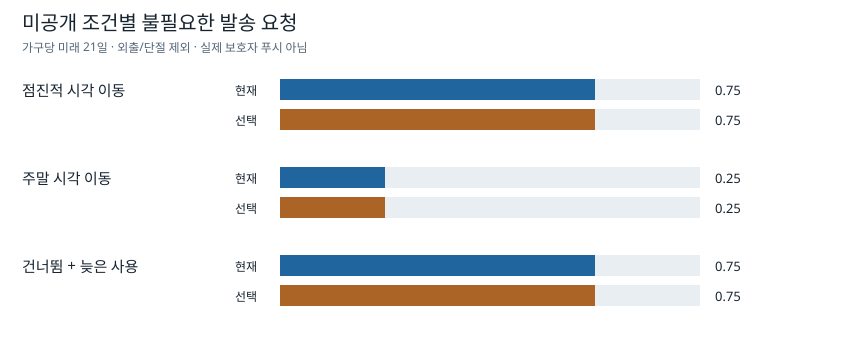

In [5]:
from html import escape
from IPython.display import SVG, display

def condition_svg(result):
    labels = {"gradual_drift": "점진적 시각 이동", "weekend_shift": "주말 시각 이동",
              "skip_and_late": "건너뜀 + 늦은 사용"}
    names = result["holdout_conditions"]
    current = result["by_condition_current"]
    selected = result["by_condition_selected"]
    peak = max(1, *(item["nuisance_per_home_21d"] for group in (current, selected)
                    for item in group.values()))
    parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="850" height="350" viewBox="0 0 850 350">',
             '<rect width="850" height="350" fill="white"/>',
             '<text x="22" y="30" font-family="sans-serif" font-size="20" fill="#182430">미공개 조건별 불필요한 발송 요청</text>',
             '<text x="22" y="52" font-family="sans-serif" font-size="12" fill="#536577">가구당 미래 21일 · 외출/단절 제외 · 실제 보호자 푸시 아님</text>']
    for index, name in enumerate(names):
        y = 79 + index * 88
        parts.append(f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="15" fill="#182430">{escape(labels[name])}</text>')
        for offset, label, value, color in ((0, "현재", current[name]["nuisance_per_home_21d"], "#21659f"),
                                            (30, "선택", selected[name]["nuisance_per_home_21d"], "#ac6426")):
            parts.extend([f'<text x="235" y="{y+offset+16}" font-family="sans-serif" font-size="12" fill="#182430">{label}</text>',
                          f'<rect x="280" y="{y+offset}" width="420" height="21" fill="#e9eef2"/>',
                          f'<rect x="280" y="{y+offset}" width="{420*value/peak:.1f}" height="21" fill="{color}"/>',
                          f'<text x="715" y="{y+offset+16}" font-family="sans-serif" font-size="13" fill="#182430">{value:.2f}</text>'])
    parts.append('</svg>')
    return ''.join(parts)

display(SVG(condition_svg(result)))


## 해석

조건별 불필요한 발송 요청이 늘어나는 곳과 놓친 시나리오를 함께 확인해야 합니다. 선택 후보가 모든 미공개 조건에서 좋아지는 것은 보장되지 않습니다. 실사용 자료 없이 얻은 성능 수치는 제품 성능 주장으로 사용하지 않습니다.


## 오프라인 결과 내보내기

아래 JSON은 Colab 세션에만 저장되며 Home Assistant의 운영 설정을 바꾸지 않습니다.


In [6]:
import json
offline_candidate = {
    "status": "offline_synthetic_experiment_only",
    "selected": result["selected"],
    "selected_settings": result["selected_settings"],
    "training": result["training"],
    "holdout_current": result["holdout_current"],
    "holdout_selected": result["holdout_selected"],
    "by_condition_current": result["by_condition_current"],
    "by_condition_selected": result["by_condition_selected"],
    "warning": "Synthetic cooker-use interruptions are not meal or safety ground truth.",
}
with open("condition_matrix_candidate.json", "w", encoding="utf-8") as handle:
    json.dump(offline_candidate, handle, ensure_ascii=False, indent=2)
print("오프라인 실험 결과 저장: condition_matrix_candidate.json")


오프라인 실험 결과 저장: condition_matrix_candidate.json
